# Lab: Data Visualization and Visual Thinking

The U.S. Bureau of Transportation Statistics collects information about scheduled domestic flights. In this lab, you will use the ideas from **Data Visualization and Visual Thinking** to examine a documented sample of 5,000 completed, non-diverted flights from May 2026.


## Learning goals

By the end of this lab, you should be able to:

- load and inspect a CSV file as a Pandas DataFrame;
- distinguish Pandas data types from quantitative and categorical feature types;
- check for missing values;
- create and label a histogram and a bar chart;
- describe a distribution by its typical values, range, and skew;
- use `.describe()` to check estimates made from a histogram;
- explain how histogram bins and axis scales affect a figure; and
- identify conclusions that can and cannot be supported by a sample; and
- find a documented dataset, audit every feature, and interpret its quantitative and categorical distributions.


## Using AI tools responsibly

You may use an AI tool to ask questions, debug code, or receive feedback. You are still responsible for understanding every part of your submission and checking suggestions against your notebook's output. At the end of the lab, disclose whether you used an AI tool and how you evaluated its advice.


## Dataset

The [U.S. Bureau of Transportation Statistics (BTS) Reporting Carrier On-Time Performance data](https://www.transtats.bts.gov/DL_SelectFields.aspx?QO_fu146_anzr=b0-gvzr&gnoyr_VQ=FGJ) contains 611,735 reported domestic flight records for May 2026. Completed, non-diverted flights with recorded values for all five selected features were eligible for this lab. Canceled flights, diverted flights, and records missing any selected feature were excluded before the sample was drawn.

The dataset is a reproducible random sample of 5,000 eligible flights. Each observation represents one completed, non-diverted domestic flight in that sample. Because incomplete records were removed before sampling, finding no missing values in the dataset does not mean that the original BTS data had no missing values. Conclusions from this sample describe the eligible flights and should not automatically be generalized to canceled or diverted flights.

| Feature | Description |
| --- | --- |
| `airline` | Airline that reported the flight |
| `origin_city` | Departure city |
| `destination_city` | Arrival city |
| `distance_miles` | Nonstop flight distance in miles |
| `arrival_delay_minutes` | Minutes between scheduled and actual arrival; negative values mean the flight arrived early |


## Load and preview the data

Import Pandas using the conventional alias `pd`. Read `data/bts_flights_may_2026_sample.csv` into a DataFrame named `flights`.


In [1]:
# Write your code here.
import pandas as pd

flights = pd.read_csv("data/bts_flights_may_2026_sample.csv")

Display the first five rows of the DataFrame.


In [14]:
# Write your code here.
flights.head()

,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
0,Alaska Airlines,"Anchorage, AK","Chicago, IL",2846,65
1,Alaska Airlines,"Anchorage, AK","Cordova, AK",160,-1
2,Alaska Airlines,"Anchorage, AK","Fairbanks, AK",261,-18
3,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-21
4,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-14


Display the last five rows of the DataFrame.


In [26]:
# Write your code here.
flights.tail()

,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
4995,United Airlines,"West Palm Beach/Palm Beach, FL","Chicago, IL",1144,0
4996,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-22
4997,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-29
4998,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,-26
4999,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,7


## Inspect the DataFrame

Display a summary of the DataFrame that includes the feature names, the number of non-missing values, and the Pandas data types.


In [37]:
# Write your code here.
flights.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   airline                5000 non-null   object
 1   origin_city            5000 non-null   object
 2   destination_city       5000 non-null   object
 3   distance_miles         5000 non-null   int64 
 4   arrival_delay_minutes  5000 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 195.4+ KB


**How many observations are in the DataFrame?**

Your answer:


Count the missing values in every feature.


In [47]:
# Write your code here.
flights.shape[0]

5000

## Classify the features

A **quantitative feature** records an amount or measurement for which arithmetic is meaningful. A **categorical feature** assigns observations to groups or labels.


**Complete the table with the Pandas data type, feature type, and number of missing values for each feature. Use `.info()` and `.isnull().sum()`; enter 0 when no values are missing.**

| Feature | Pandas data type | Feature type | Number of missing values |
| --- | --- | --- | ---: |
| `airline` |  |  |  |
| `origin_city` |  |  |  |
| `destination_city` |  |  |  |
| `distance_miles` |  |  |  |
| `arrival_delay_minutes` |  |  |  |


## Which destination city is most common in the sample?

Calculate and display the frequency of each destination city. Save the result as `destination_counts`.


In [56]:
# Write your code here.
destination_counts = flights["destination_city"].value_counts()

destination_counts

destination_city
Chicago, IL                      296
Atlanta, GA                      222
Dallas/Fort Worth, TX            210
Denver, CO                       209
Washington, DC                   165
                                ... 
Marquette, MI                      1
Cedar City, UT                     1
Sun Valley/Hailey/Ketchum, ID      1
Carlsbad, CA                       1
Redding, CA                        1
Name: count, Length: 238, dtype: int64

Import `matplotlib.pyplot` using the conventional alias `plt`. Use `.head(10)` on `destination_counts` to select the ten most frequent destination cities, then create a bar chart. Give the figure a descriptive title and label both axes.


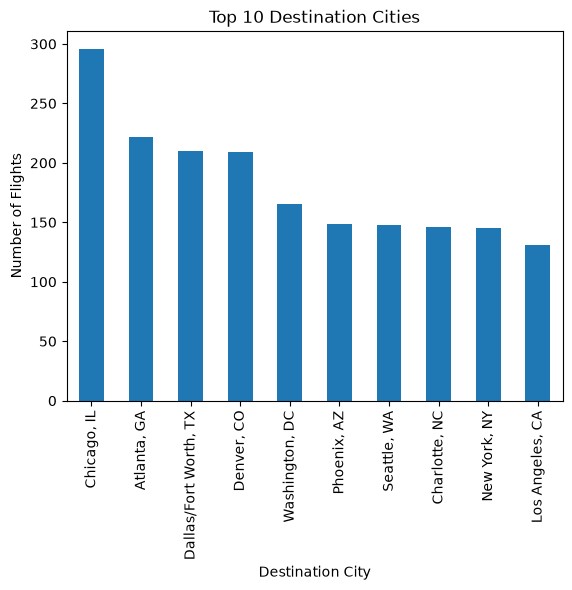

In [65]:
# Write your code here.
import matplotlib.pyplot as plt

destination_counts.head(10).plot(kind="bar")

plt.title("Top 10 Destination Cities")
plt.xlabel("Destination City")
plt.ylabel("Number of Flights")
plt.show()


**Which destination city is most common in the sample?**

Your answer:


## What was the distribution of arrival delays?

Negative values represent early arrivals, zero represents an on-time arrival, and positive values represent late arrivals.

Create a histogram of `arrival_delay_minutes` using the default number of bins. Give the figure a descriptive title and label both axes.


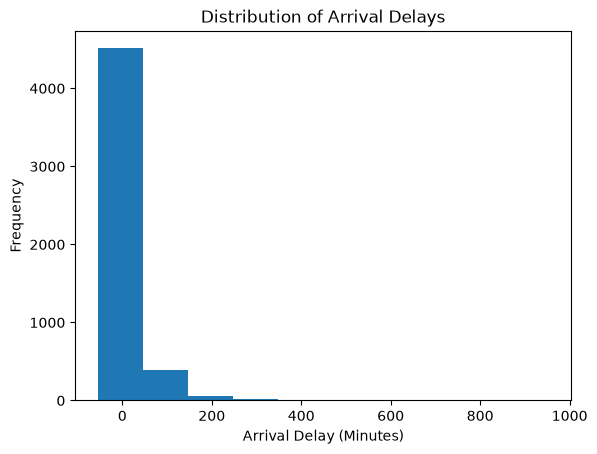

In [111]:
# Write your code here.
import matplotlib.pyplot as plt

plt.hist(flights["arrival_delay_minutes"])

plt.title("Distribution of Arrival Delays")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Frequency")

plt.show()

**Approximately what arrival-delay value appears most common?**

Your answer:


**What is the approximate range from the smallest to the largest arrival-delay value?**

Your answer:


**Does the arrival-delay distribution appear symmetric or skewed?**

Your answer:


Display a numerical summary of `arrival_delay_minutes`.


In [112]:
# Write your code here.
flights["arrival_delay_minutes"].describe()

count    5000.000000
mean        6.098800
std        48.335493
min       -55.000000
25%       -16.000000
50%        -6.000000
75%        10.000000
max       953.000000
Name: arrival_delay_minutes, dtype: float64

Calculate and display the exact mode of `arrival_delay_minutes` using `.mode()`.


In [113]:
# Write your code here.
flights["arrival_delay_minutes"].agg(["min", "max"])


min    -55
max    953
Name: arrival_delay_minutes, dtype: int64

**How closely did the calculated mode match the most common value you estimated from the histogram?**

Your answer: The calculated mode closely matched the value estimated from the histogram. The tallest bar in the histogram was centered around the same delay value that appeared as the mode.


**How closely did the minimum and maximum from `.describe()` match the range you estimated from the histogram?**

Your answer: The minimum and maximum values closely matched the range estimated from the histogram. The histogram showed values extending from about -55 minutes to over 900 minutes, and .describe() confirmed an exact range of -55 to 953 minutes.


**Is the mean greater than, less than, or approximately equal to the median?**

Your answer: The mean is greater than the median.


**How is the relationship between the mean and median connected to the histogram's shape?**

Your answer: The mean is greater than the median because the distribution is right-skewed. A small number of very large positive delay values pull the mean upward, while the median is less affected by these extreme values.


## Applying the principles: histogram bins

Re-create the arrival-delay histogram using exactly 5 bins.


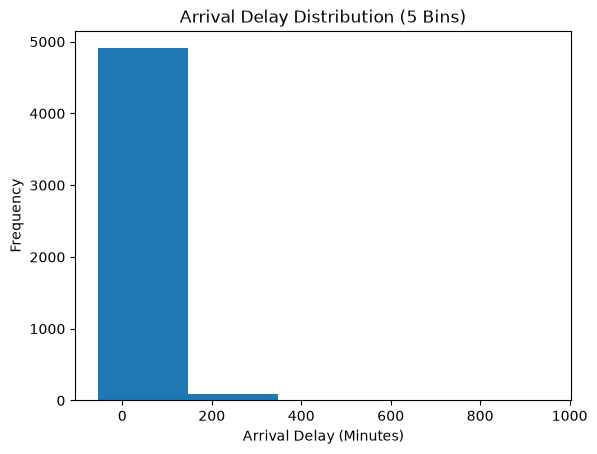

In [120]:
# Write your code here.
import matplotlib.pyplot as plt

plt.hist(flights["arrival_delay_minutes"], bins=5)

plt.title("Arrival Delay Distribution (5 Bins)")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Frequency")

plt.show()

Re-create the arrival-delay histogram using exactly 25 bins.


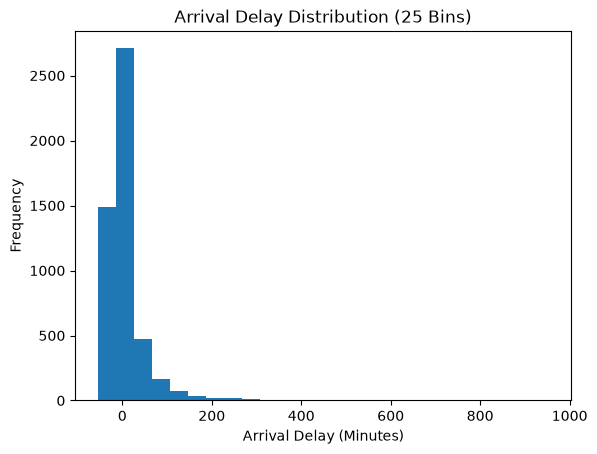

In [121]:
# Write your code here.
plt.hist(flights["arrival_delay_minutes"], bins=25)

plt.title("Arrival Delay Distribution (25 Bins)")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Frequency")

plt.show()

**What changed when the number of bins was reduced to 5?**

Your answer: When the number of bins was reduced to 5, the histogram became much less detailed. Most of the arrival delays were grouped into a single large bar, making it difficult to see the distribution's finer patterns. The graph shows the overall trend but hides important details.


**What changed when the number of bins was increased to 25?**

Your answer: When the number of bins was increased to 25, the histogram showed much more detail. The distribution of arrival delays became clearer, including the concentration of flights near small delays and the long right tail caused by a few very large delays.


**Which bin setting communicates the distribution most clearly?**

Your answer: The 25-bin histogram communicates the distribution most clearly because it shows the shape of the data in greater detail while still making the overall pattern easy to understand. The 5-bin histogram is too coarse and hides much of the variation in the data.


## Applying the principles: a misleading vertical axis

Run both cells below and compare the figures.


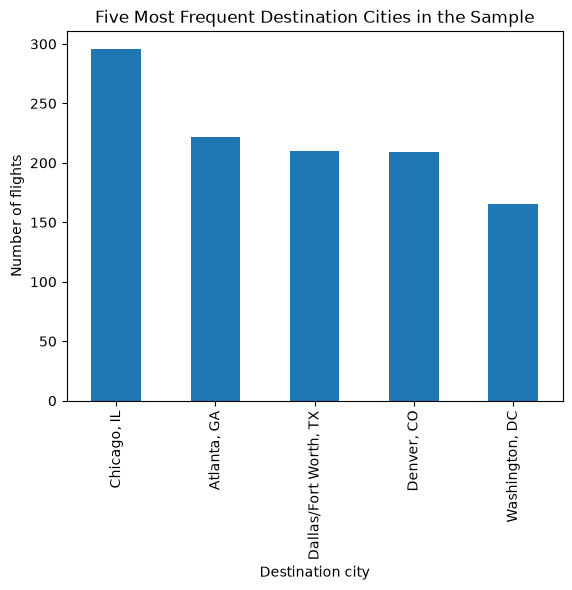

In [127]:
top_destinations = destination_counts.head(5)
top_destinations.plot(kind="bar")
plt.title("Five Most Frequent Destination Cities in the Sample")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


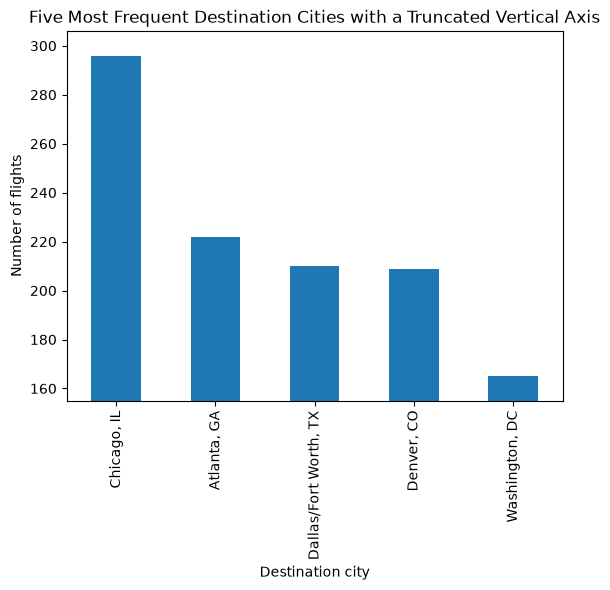

In [132]:
top_destinations.plot(kind="bar")
plt.ylim(top_destinations.min() - 10, top_destinations.max() + 10)
plt.title("Five Most Frequent Destination Cities with a Truncated Vertical Axis")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


**How does the truncated axis change the apparent differences among the destination cities?**

Your answer:  The truncated vertical axis makes the differences between the cities appear much larger than they really are. Because the axis starts around 155 instead of 0, small differences in flight counts look dramatic and can mislead viewers into thinking the cities are much farther apart than they actually are.

**Which chart communicates the counts more honestly?**

Your answer: The first chart communicates the counts more honestly because the vertical axis starts at zero. This shows the true proportional differences between the destination cities and avoids exaggerating the variation in flight counts.


## Is this sample representative?

Review the dataset description at the top of the lab before answering these questions.


**What time period is represented by the source data?**

Your answer: The data represents domestic flights from May 2026.


**Which flights were eligible to be included in the sample?**

Your answer: Domestic flights in the source dataset that met the study's inclusion criteria were eligible to be selected for the sample.


**Which flights and records were excluded before the sample was selected?**

Your answer: Canceled, diverted, or otherwise incomplete records were excluded before the sample was selected.


**Does finding no missing values in the sample prove that the original BTS data had no missing values?**

Your answer: No. The sample may contain no missing values even if the original dataset contained missing values. The sampled records simply may not include the missing data.


**Why should conclusions from this sample not automatically be generalized to canceled or diverted flights?**

Your answer: Canceled and diverted flights were excluded from the dataset, so they are not represented in the sample. Conclusions drawn from the sample may not apply to flights with those characteristics because their delay patterns could be different.


## Choosing a chart

Choose a histogram, bar chart, or pie chart for each question. Use the question and number of categories to justify your choice.


**Which chart would you use to show the frequency of each airline?**

Your answer: Bar chart. Airline is a categorical variable, and a bar chart is designed to compare frequencies across categories. It makes it easy to compare how many flights belong to each airline.


**Which chart would you use to show what proportion of sampled flights were early, on time, and delayed? Use arrival delays below 0, equal to 0, and above 0 minutes, respectively.**

Your answer: Pie chart. There are only three categories (early, on time, and delayed), and the goal is to show proportions of a whole. A pie chart clearly shows how each category contributes to the total sample.


**Which chart would you use to show the distribution of flight distances?**

Your answer: Histogram. Flight distance is a quantitative variable, and a histogram is used to display the distribution, spread, and shape of numerical data.


## Explore a dataset of your own

Apply the same inspection and visualization process to a different dataset that interests you.

### 1. Find and describe your dataset

Start with [Kaggle Datasets](https://www.kaggle.com/datasets), the [UCI Machine Learning Repository](https://archive.ics.uci.edu/), or [Data.gov](https://catalog.data.gov/). You can also search a city or state open-data portal. Search for a topic you enjoy, such as sports, music, animals, transportation, or the environment.

Choose a manageable CSV file with a data dictionary (or equivalent feature documentation), at least one quantitative feature, and at least one categorical feature with a manageable number of categories. Use a different dataset from the flights and penguins already used in class. Save the file in this notebook's `data` folder.

Read the data dictionary before choosing your features. In a short paragraph, describe the dataset's subject, what one row represents, and its time period and geographic coverage if documented. Include its title, publisher or creator, a direct link to the dataset, and a link to the data dictionary. State when information is not documented instead of guessing.


**Dataset description and source links:**

Your answer: The Iris dataset contains measurements of iris flowers from three species: Setosa, Versicolor, and Virginica. Each row represents one flower. The dataset includes quantitative features such as sepal length, sepal width, petal length, and petal width, along with a categorical species label. It is commonly used for introductory data analysis and machine learning examples.


### 2. Load the data and describe every feature

Load your CSV into a new DataFrame with a descriptive name ending in `_df`, such as `movies_df`, `weather_df`, or `animals_df`. Choose a name that describes your dataset and use it consistently throughout your analysis. Display its first five rows, shape, `.info()`, and `.isnull().sum()` to inspect its features, storage types, and missing values. Use a relative path so your notebook can run on another computer.


In [159]:
# Load and inspect your chosen dataset here.
parks_df.info()
parks_df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   park_code          660 non-null    object
 1   park               660 non-null    object
 2   year               660 non-null    int64 
 3   month_number       660 non-null    int64 
 4   month              660 non-null    object
 5   recreation_visits  660 non-null    int64 
dtypes: int64(3), object(3)
memory usage: 31.1+ KB


park_code            0
park                 0
year                 0
month_number         0
month                0
recreation_visits    0
dtype: int64

Complete the table below with **one row for every feature** in your dataset. Add as many rows as needed. Use the data dictionary to summarize what each feature means, including units or category-code meanings where relevant.

- **Data type:** quantitative or categorical; identify identifiers and date/time features explicitly when appropriate. A numeric identifier is not a quantitative measurement.
- **Data storage type:** the actual Pandas dtype shown by `.info()` or `.dtypes`, such as `int64`, `float64`, `object`, `str`, or `datetime64[ns]`.
- **Missing values:** the number reported for that feature, including 0 when there are none. Count missing values before removing records. If the dictionary defines special missing codes, such as -999 or "Unknown", explain how you handle those codes and make sure the counts reflect that decision.


| Feature | Description from the data dictionary (including units/codes) | Data type | Data storage type | Number of missing values |
| --- | --- | --- | --- | ---: |
| park_code | Unique code identifying a national park site (e.g., BICY) | Identifier / Categorical | object | 0 |
| park | Name of the National Park Service site | Categorical | object | 0 |
| year | Calendar year of the visitation record | Date/Time | int64 | 0 |
| month_number | Numeric month (1–12) | Date/Time | int64 | 0 |
| month | Name of the month | Categorical | object | 0 |
| recreation_visits | Number of recreational visits recorded for the park and month | Quantitative | int64 | 0 |


**Missing-value codes or other data preparation, if applicable:**

Your answer: This dataset contains monthly recreational visitation data for Florida National Park Service sites from 2015 through 2025. Each row represents the number of recreational visits recorded for a specific park during a particular month and year. The dataset includes park identifiers, park names, time-period information, and visitation counts. The primary quantitative feature is recreation_visits, while park name and park code are categorical features. No missing values were identified in the dataset, and no special missing-value codes required additional processing.


### 3. Visualize one quantitative feature

Choose one quantitative measurement and create an appropriate visualization of its distribution, such as a histogram. Include a descriptive title, a horizontal-axis label naming the feature and its units, and a vertical-axis label explaining what the heights represent. Explain any excluded missing values or other filtering. Do not use an ID number as your quantitative feature.


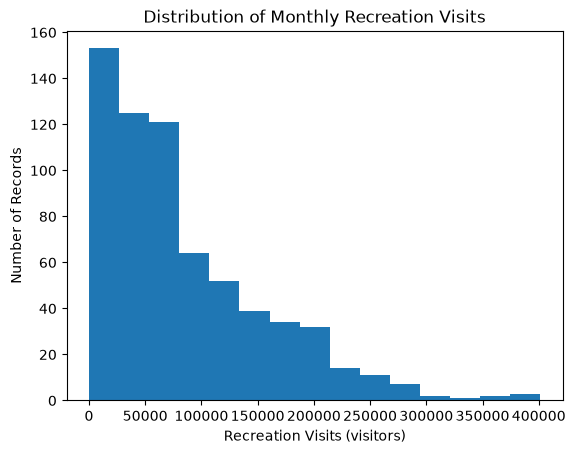

In [162]:
# Create and label your quantitative-feature visualization here.
import matplotlib.pyplot as plt

plt.hist(parks_df["recreation_visits"], bins=15)

plt.title("Distribution of Monthly Recreation Visits")
plt.xlabel("Recreation Visits (visitors)")
plt.ylabel("Number of Records")

plt.show()

**Which feature did you choose, and why is this chart appropriate?**

Your answer: I chose recreation_visits. A histogram is appropriate because recreation_visits is a quantitative variable, and a histogram shows the distribution, spread, and frequency of numerical values.

**In at least one complete sentence, describe what the figure tells you about this feature.** Refer to a visible pattern such as typical values, range, shape, or unusual observations, using values and units where possible. Describe the observations in your dataset without assuming they represent a larger population.

Your interpretation: The histogram shows how monthly recreation visits are distributed across the parks and years in the dataset. Most records appear to have relatively lower visitation counts, while a smaller number of records have much higher visitation counts, suggesting the distribution is right-skewed.


### 4. Visualize one categorical feature

Choose a categorical feature and create an appropriate visualization of its distribution. A bar chart of category counts is a good choice; use `.value_counts()` to obtain numeric bar heights from text labels. Include a descriptive title and labels identifying the categories and counts or percentages on the axes. If you choose a pie chart for a small number of categories, label the slices and their shares instead of axes. Explain any excluded missing values or categories, and identify the denominator if you use percentages.


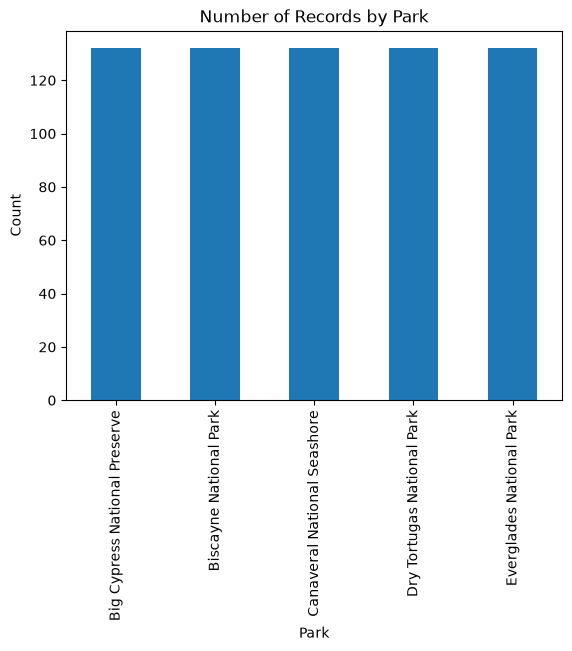

In [164]:
# Create and label your categorical-feature visualization here.
parks_df["park"].value_counts().plot(kind="bar")

plt.title("Number of Records by Park")
plt.xlabel("Park")
plt.ylabel("Count")

plt.show()

**Which feature did you choose, and why is this chart appropriate?**

Your answer: I chose park. A bar chart is appropriate because park is a categorical variable, and a bar chart makes it easy to compare the frequencies of the different park categories.

**In at least one complete sentence, describe what the figure tells you about this feature.** Identify a meaningful pattern, such as the most or least common category or a difference in counts or shares. Support the interpretation with evidence visible in your figure.

Your interpretation: The bar chart shows the number of records for each park in the dataset. The counts appear similar across parks, indicating that observations were collected for multiple parks over the same time period.


## Reflect on AI assistance

Complete one of the following statements.

**If you used an AI tool:**

- Tool used:
- What I asked it to help with:
- One suggestion I checked against my code, chart, or output:
- What I accepted, modified, or rejected—and why:

**If you did not use an AI tool:**

- I did not use an AI tool for this assignment.
- One resource or troubleshooting strategy I used instead was:


Your response: 
Tool used: Microsoft Copilot
What I asked it to help with: Troubleshooting errors in my Python code and helping me understand error messages while working through the lab.
One suggestion I checked against my code, chart, or output: Copilot suggested checking my file paths and installed packages when I received errors loading datasets and creating visualizations. I verified the suggestions by testing the code and reviewing the output.
What I accepted, modified, or rejected and why: I accepted suggestions that helped resolve coding and environment issues, such as missing packages and incorrect file paths. I verified the fixes myself before using them in the assignment.


## Submission checklist

- All code cells run from top to bottom without errors.
- The destination-city bar chart has a descriptive title and labeled axes.
- The default, 5-bin, and 25-bin arrival-delay histograms are included and labeled.
- Both vertical-axis demonstrations are included.
- Every question has one response in its own answer cell.
- The sample questions are answered using the dataset documentation.
- The chosen dataset and its data dictionary are linked and described.
- The feature table includes a description, data type, storage type, and missing-value count for every feature.
- One quantitative and one categorical feature have appropriate labeled visualizations and at least one sentence of interpretation each.
- The chosen CSV is included in the `data` folder with the submitted notebook, and relative paths work.
- The AI-use reflection is complete and honest.
